# 🧠 Odysseus Unified Predictive Maintenance: Inferential Statistics, Multiclass Diagnosis, SHAP XAI & Holt-Winters Forecasting

**Proyecto:** Odysseus AI Platform & Predictive MLOps Framework  
**Lead Architect:** [Guillen Concepcion](https://www.linkedin.com/in/guillen-concepcion-25266b127) *(Senior Data Scientist & MLOps Engineer)*  
**Componente:** Suite Unificada de 5 Etapas — SQL Feature Store, Pruebas Inferenciales, Benchmark Multiclase, XAI SHAP, Pronóstico ISO-10816 y Despliegue ONNX/Lambda  

---

## 🧭 Resumen Ejecutivo (CoNVO Framework)
* **Contexto:** Las turbinas industriales monitorizadas por Apache Flink generan flujos continuos de telemetría (temperatura, vibración RMS, presión y potencia) almacenados en particiones Parquet sobre Amazon S3.
* **Necesidad:** Superar la detección binaria simple incorporando:
  1. **Diagnóstico Multiclase de Causa Raíz:** Distinguir entre `NORMAL`, `OVERHEAT_FAULT`, `BEARING_VIBRATION_WEAR` y `PRESSURE_VALVE_DROP`.
  2. **Rigor Estadístico Inferencial:** Validar con pruebas paramétricas y no paramétricas la separabilidad física de los regímenes antes del modelado.
  3. **Partición Cronológica Tripartita (70/15/15):** Calibrar el umbral óptimo $\tau^*$ estrictamente en *Validation* para erradicar el *Validation Leakage*.
  4. **Explicabilidad (XAI) y Pronóstico de Umbral Crítico:** Cuantificar la atribución causal con **SHAP (`TreeExplainer`)** y proyectar el cruce del límite normativo **ISO-10816 ($6.5\text{ mm/s}$)** con **Holt-Winters**.


## 1. Extracción y Feature Store en SQL (`AthenaDataLakeConnector` & `ATHENA_FEATURE_STORE_SQL`)
Ejecutamos la consulta SQL analítica en **DuckDB** (emulando **Amazon Athena / Trino**) con funciones de ventana (`LAG` 1h/3h/6h, `AVG`, `STDDEV_SAMP`, `MAX` en 6h y 24h), derivadas discretas ($d\text{Sensor}/dt$) e índices termo-mecánicos.

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

sys.path.insert(0, os.path.abspath("../scripts"))
from iot_predictive_maintenance_suite import (
    ATHENA_FEATURE_STORE_SQL,
    AthenaDataLakeConnector,
    run_descriptive_and_inferential_analysis,
    train_and_evaluate_models,
    forecast_sensor_critical_threshold,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

connector = AthenaDataLakeConnector()
df_features = connector.synthesize_lakehouse_telemetry(n_machines=12, n_hours=720)
print(f"[+] Matriz del Feature Store extraída: {df_features.shape[0]:,} filas x {df_features.shape[1]} columnas")
print(f"[+] Prevalencia Pre-Falla (<=12h): {df_features['target_binary'].mean()*100:.2f}%")
print("\nDistribución de Modos de Falla (target_multiclass):")
print(df_features["target_multiclass"].value_counts())
df_features.head(5)

[+] Matriz del Feature Store extraída: 8,568 filas x 36 columnas
[+] Prevalencia Pre-Falla (<=12h): 6.72%

Distribución de Modos de Falla (target_multiclass):
target_multiclass
NORMAL                    7992
BEARING_VIBRATION_WEAR     192
PRESSURE_VALVE_DROP        192
OVERHEAT_FAULT             192
Name: count, dtype: int64


,sensor_id,timestamp,temperature,vibration,pressure,power_kw,temp_lag_1h,temp_lag_3h,temp_lag_6h,vib_lag_1h,vib_lag_3h,vib_lag_6h,press_lag_1h,press_lag_3h,press_lag_6h,temp_roll_avg_6h,temp_roll_std_6h,temp_roll_avg_24h,temp_roll_std_24h,temp_roll_max_24h,vib_roll_avg_6h,vib_roll_std_6h,vib_roll_avg_24h,vib_roll_std_24h,vib_roll_max_24h,press_roll_avg_24h,press_roll_std_24h,thermo_vib_interaction,vib_pressure_ratio,target_binary,target_multiclass,d_temp_dt_1h,d_temp_dt_6h,d_vib_dt_1h,d_vib_dt_6h,d_press_dt_1h
0,TURBINE-001,2026-10-12 06:00:00,66.710898,1.853324,102.524245,450.134855,64.087023,65.900009,62.695400,1.808907,1.919927,1.656968,102.379705,101.539958,102.596593,64.524237,1.533651,64.262974,1.561370,66.710898,1.723195,0.213901,1.713734,0.196862,1.919927,102.606301,0.589400,123.636883,0.018077,0,NORMAL,2.623875,0.669250,0.044417,0.032726,0.144540
1,TURBINE-002,2026-10-12 06:00:00,65.726466,1.877250,103.895003,454.309342,65.752235,63.130012,64.209365,1.703380,1.881002,1.751329,103.087730,102.215669,101.394763,64.337055,1.225643,64.318814,1.119895,65.752235,1.792123,0.122922,1.786296,0.113267,1.899858,102.266864,1.004504,123.385014,0.018069,0,NORMAL,-0.025770,0.252850,0.173870,0.020987,0.807272
2,TURBINE-003,2026-10-12 06:00:00,64.031276,1.802570,102.588972,444.128064,66.134057,62.883755,58.886996,1.886576,1.500929,1.496256,102.502481,103.716456,101.257849,63.950883,1.738398,63.227471,2.486289,66.134057,1.704434,0.164212,1.674694,0.169300,1.886576,102.214114,0.851613,115.420878,0.017571,0,NORMAL,-2.102781,0.857380,-0.084005,0.051052,0.086491
3,TURBINE-004,2026-10-12 06:00:00,61.539429,1.500253,103.859850,450.842258,63.420623,63.349070,60.314521,2.002441,1.916620,1.994655,102.228586,102.785192,103.147188,63.419785,1.194430,62.976176,1.602001,65.116075,1.788184,0.178537,1.817680,0.180701,2.002441,102.771705,0.661343,92.324698,0.014445,0,NORMAL,-1.881194,0.204151,-0.502188,-0.082400,1.631264
4,TURBINE-005,2026-10-12 06:00:00,63.315042,1.892355,101.609860,456.810752,63.385849,61.427902,63.597100,1.803916,1.733075,1.348410,104.663135,103.412963,101.184404,63.323387,1.102490,63.362489,1.011734,64.684539,1.770508,0.110483,1.710208,0.188745,1.892355,102.429116,1.402853,119.814550,0.018624,0,NORMAL,-0.070807,-0.047010,0.088440,0.090657,-3.053275


## 2. Análisis Estadístico Descriptivo Estratificado y Pruebas de Hipótesis Inferenciales
De acuerdo con las directrices de **AGENTS.md**, reportamos **Mediana ($P_{50}$) y Rango Intercuartílico ($\mathrm{IQR}$)** junto con Media y Desviación Estándar, y ejecutamos las 6 pruebas de hipótesis formales:
* **Prueba $t$ de Welch:** Contraste paramétrico con varianzas desiguales.
* **Prueba $U$ de Mann-Whitney:** Contraste no paramétrico robusto frente a alta asimetría.
* **Prueba de Kolmogorov-Smirnov ($D_{\mathrm{KS}}$):** Divergencia máxima entre distribuciones acumuladas empíricas.
* **Tamaño del Efecto ($d$ de Cohen):** Magnitud física del cambio en unidades de desviación estándar agrupada.
* **ANOVA de una vía ($F$-test):** Separabilidad entre los 4 modos multiclase.
* **Augmented Dickey-Fuller (ADF):** Contraste de raíz unitaria y estacionariedad.

In [2]:
stats_res = run_descriptive_and_inferential_analysis(df_features)
print("=== ESTADÍSTICOS DESCRIPTIVOS ESTRATIFICADOS (NORMAL vs PRE-FALLA <=12H) ===")
display(stats_res["descriptive"].round(4))

print("\n=== BATERÍA DE 6 PRUEBAS DE HIPÓTESIS INFERENCIALES ===")
display(stats_res["inferential"])

=== ESTADÍSTICOS DESCRIPTIVOS ESTRATIFICADOS (NORMAL vs PRE-FALLA <=12H) ===


,Sensor,Regime,Count,Mean,Std,Median_P50,IQR,Skewness,Kurtosis
0,temperature,Normal (0),7992,61.9837,2.2605,61.9544,3.3961,-0.0077,-0.5316
1,temperature,Pre-Failure <=12h (1),576,70.1835,7.3346,68.5527,6.7686,1.3677,1.7379
2,vibration,Normal (0),7992,1.6168,0.2585,1.6115,0.3599,0.2469,-0.0288
3,vibration,Pre-Failure <=12h (1),576,3.1766,1.2826,2.9055,1.2316,1.4562,1.9817
4,pressure,Normal (0),7992,101.9928,1.1390,101.9757,1.5734,0.0311,-0.2268
5,pressure,Pre-Failure <=12h (1),576,98.2211,6.8961,101.3400,5.5125,-1.6671,1.6774



=== BATERÍA DE 6 PRUEBAS DE HIPÓTESIS INFERENCIALES ===


,Sensor,Welch_t,Welch_p,MannWhitney_U,MannWhitney_p,KS_stat,KS_p,Cohens_d,ANOVA_F,ANOVA_p,ADF_stat,ADF_p
0,temperature,26.73972,2.113172e-103,4189977.0,7.017172e-238,0.694789,1.006006e-256,2.832897,1968.790728,0.0,-10.420762,1.707106e-18
1,vibration,29.14375,1.396906e-115,4404114.0,2.233855e-294,0.815847,1.823102e-321,3.752704,3390.796398,0.0,-8.336497,3.261672e-13
2,pressure,-13.11372,1.421260e-34,1601174.0,2.484568e-34,0.295327,5.651515e-42,-1.797593,3337.191763,0.0,-7.992760,2.449363e-12


## 3. Benchmark de Ensambles (Partición Cronológica 70/15/15), Diagnóstico Multiclase y Explicabilidad SHAP
Evaluamos tres arquitecturas de árboles (`LightGBM_EWS`, `XGB_HistGradientBoosting`, `RandomForest_Balanced`), calibrando el umbral de decisión $\tau^*$ exclusivamente en el pliegue de **Validación (15%)** bajo restricción de precisión mínima en planta ($\ge 80\%$).

In [3]:
ml_res = train_and_evaluate_models(df_features)

bench_rows = []
for name, b in ml_res["benchmark"].items():
    bench_rows.append({
        "Model": name,
        "PR_AUC": round(b["pr_auc"], 4),
        "ROC_AUC": round(b["roc_auc"], 4),
        "Optimal_Tau_Val": round(b["opt_tau"], 3),
        "Precision_Test": f"{b['precision']*100:.2f}%",
        "Recall_Test": f"{b['recall']*100:.2f}%",
        "F1_Score_Test": round(b["f1"], 4),
        "Net_Savings_USD": f"${b['net_savings_usd']:,.2f}",
    })

df_bench = pd.DataFrame(bench_rows)
print("=== RESULTADOS DEL BENCHMARK EN TEST (SIN DATA LEAKAGE) ===")
display(df_bench)

print("\n=== TOP 10 VARIABLES POR IMPACTO CAUSAL GLOBAL |SHAP| ===")
display(ml_res["shap_df"].head(10).round(4))

=== RESULTADOS DEL BENCHMARK EN TEST (SIN DATA LEAKAGE) ===


,Model,PR_AUC,ROC_AUC,Optimal_Tau_Val,Precision_Test,Recall_Test,F1_Score_Test,Net_Savings_USD
0,LightGBM_EWS,0.9361,0.9741,0.070,96.80%,84.03%,0.8996,"$6,048,000.00"
1,XGB_HistGradientBoosting,0.9454,0.9791,0.305,96.80%,84.03%,0.8996,"$6,048,000.00"
2,RandomForest_Balanced,0.9391,0.9764,0.255,95.20%,82.64%,0.8848,"$5,947,000.00"



=== TOP 10 VARIABLES POR IMPACTO CAUSAL GLOBAL |SHAP| ===


,Feature,Mean_Abs_SHAP
0,vib_pressure_ratio,0.9323
1,vib_lag_1h,0.7024
2,vibration,0.3598
3,pressure,0.3470
4,temperature,0.3155
5,press_roll_avg_24h,0.3081
6,thermo_vib_interaction,0.3014
7,vib_roll_max_24h,0.3003
8,vib_roll_avg_24h,0.2750
9,press_lag_1h,0.2630


## 4. Pronóstico de Serie Temporal hacia el Umbral Crítico ISO-10816 ($6.5\text{ mm/s}$)
Ajustamos un modelo **Holt-Winters Exponential Smoothing** con estacionalidad diurna de 24 horas e intervalos de predicción al 95% para estimar la ventana de intervención antes de cruzar el límite crítico de vibración.

In [4]:
forecast_res = forecast_sensor_critical_threshold(df_features, critical_limit_mms=6.5, forecast_horizon_hours=24)
print(f"Límite Crítico Normativo ISO-10816: {forecast_res['critical_limit_mms']} mm/s")
print(f"Cruce proyectado (Banda Superior IC 95%): +{forecast_res['hours_to_critical_upper95']} horas")
forecast_df = pd.DataFrame({
    "Forecast_Mean_mms": forecast_res["forecast_mean"],
    "Lower_95_CI": forecast_res["lower_95"],
    "Upper_95_CI": forecast_res["upper_95"],
}).round(3)
display(forecast_df.head(10))

Límite Crítico Normativo ISO-10816: 6.5 mm/s
Cruce proyectado (Banda Superior IC 95%): +20 horas


,Forecast_Mean_mms,Lower_95_CI,Upper_95_CI
2026-11-11 00:00:00,5.219,4.983,5.454
2026-11-11 01:00:00,5.309,5.059,5.559
2026-11-11 02:00:00,5.420,5.156,5.684
2026-11-11 03:00:00,5.448,5.170,5.725
2026-11-11 04:00:00,5.686,5.396,5.976
2026-11-11 05:00:00,5.711,5.409,6.014
2026-11-11 06:00:00,5.748,5.434,6.062
2026-11-11 07:00:00,5.918,5.593,6.244
2026-11-11 08:00:00,5.707,5.371,6.043
2026-11-11 09:00:00,5.912,5.566,6.259


## 5. Galería Completa de las 6 Visualizaciones Ejecutivas
Visualizamos los 6 paneles exportados en `outputs/iot_predictive_maintenance/figures/`:


--- 01_telemetry_degradation_timeline.png ---


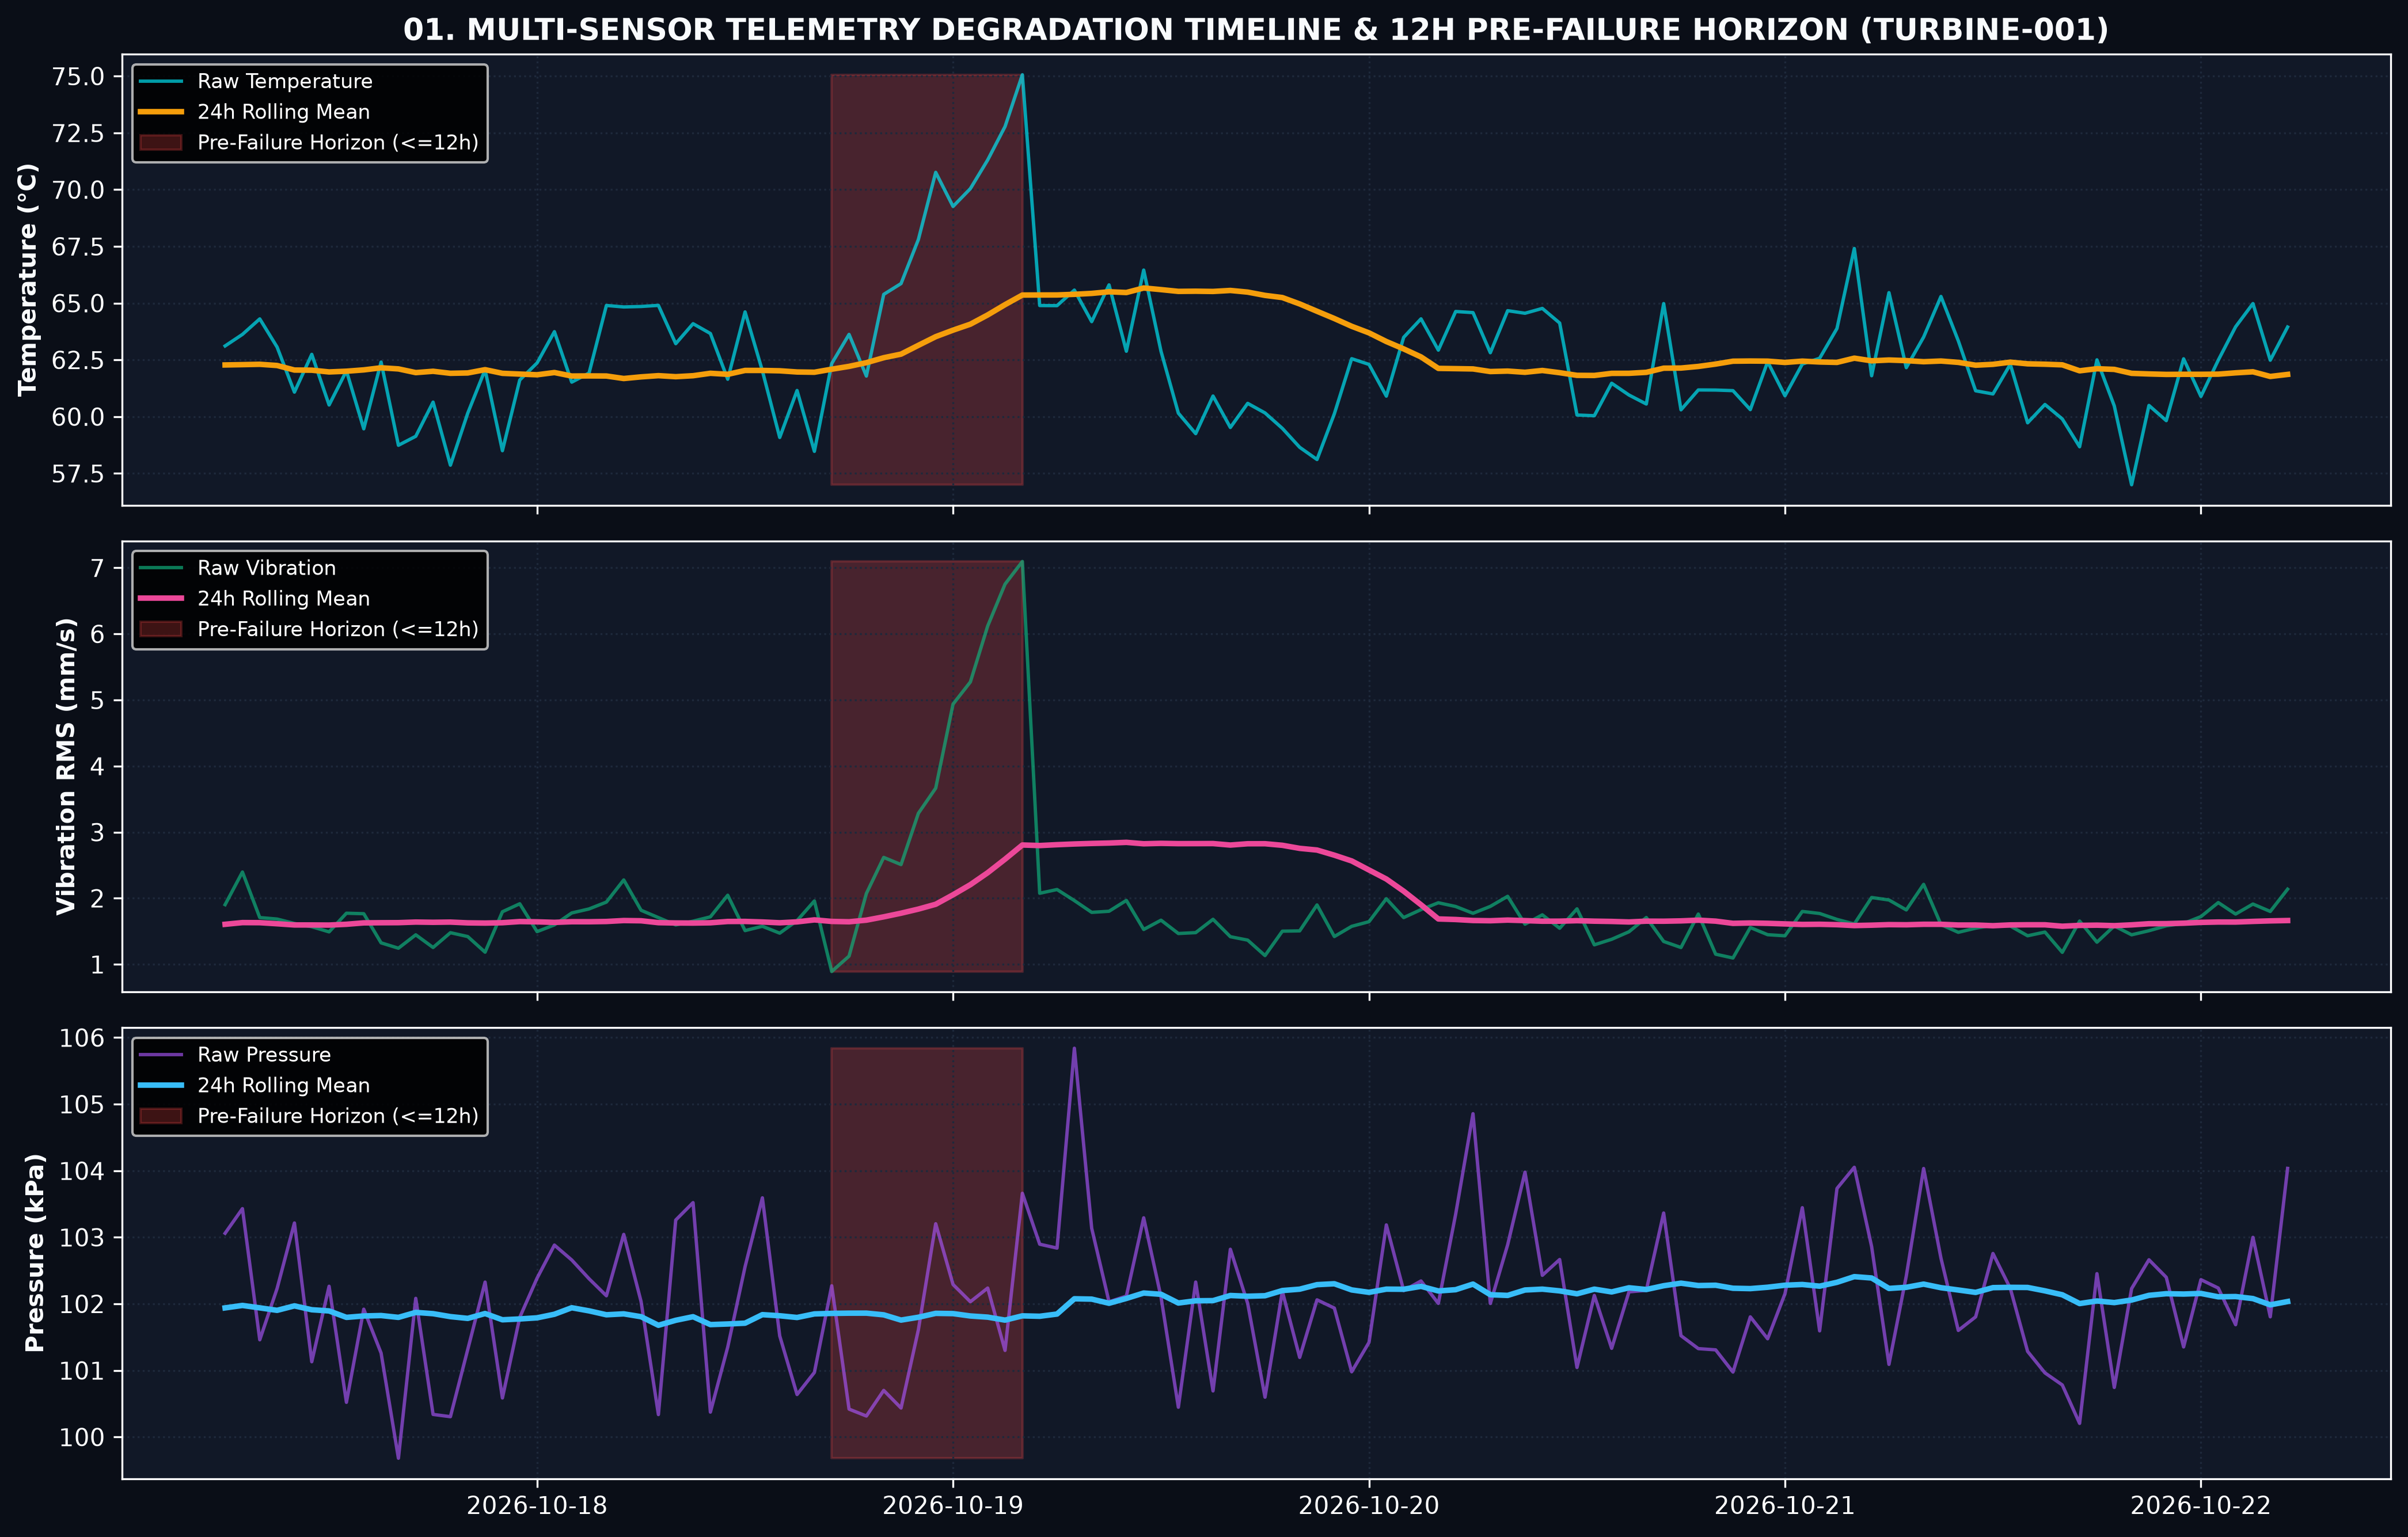


--- 02_inferential_distributions_violin.png ---


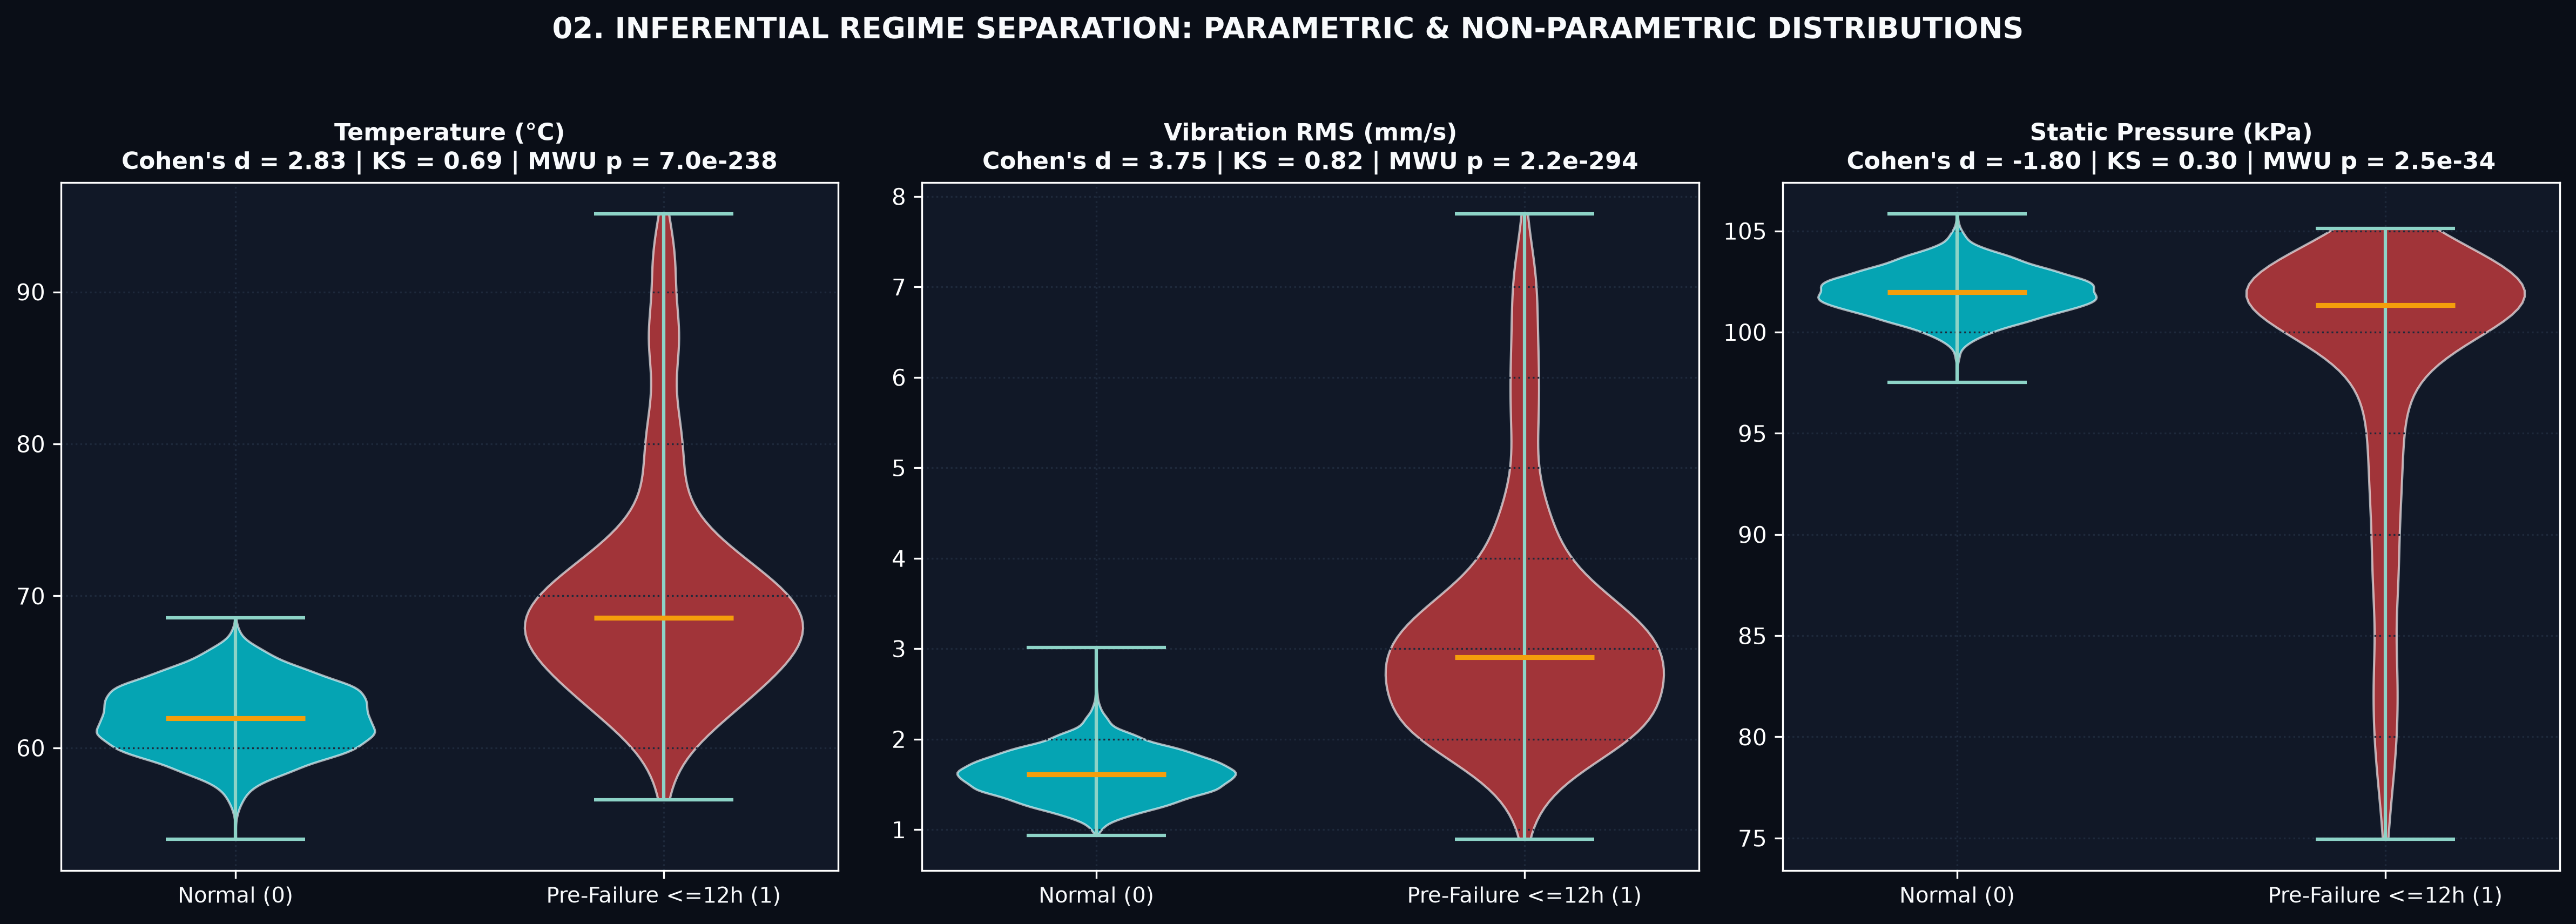


--- 03_model_benchmark_pr_roc_curves.png ---


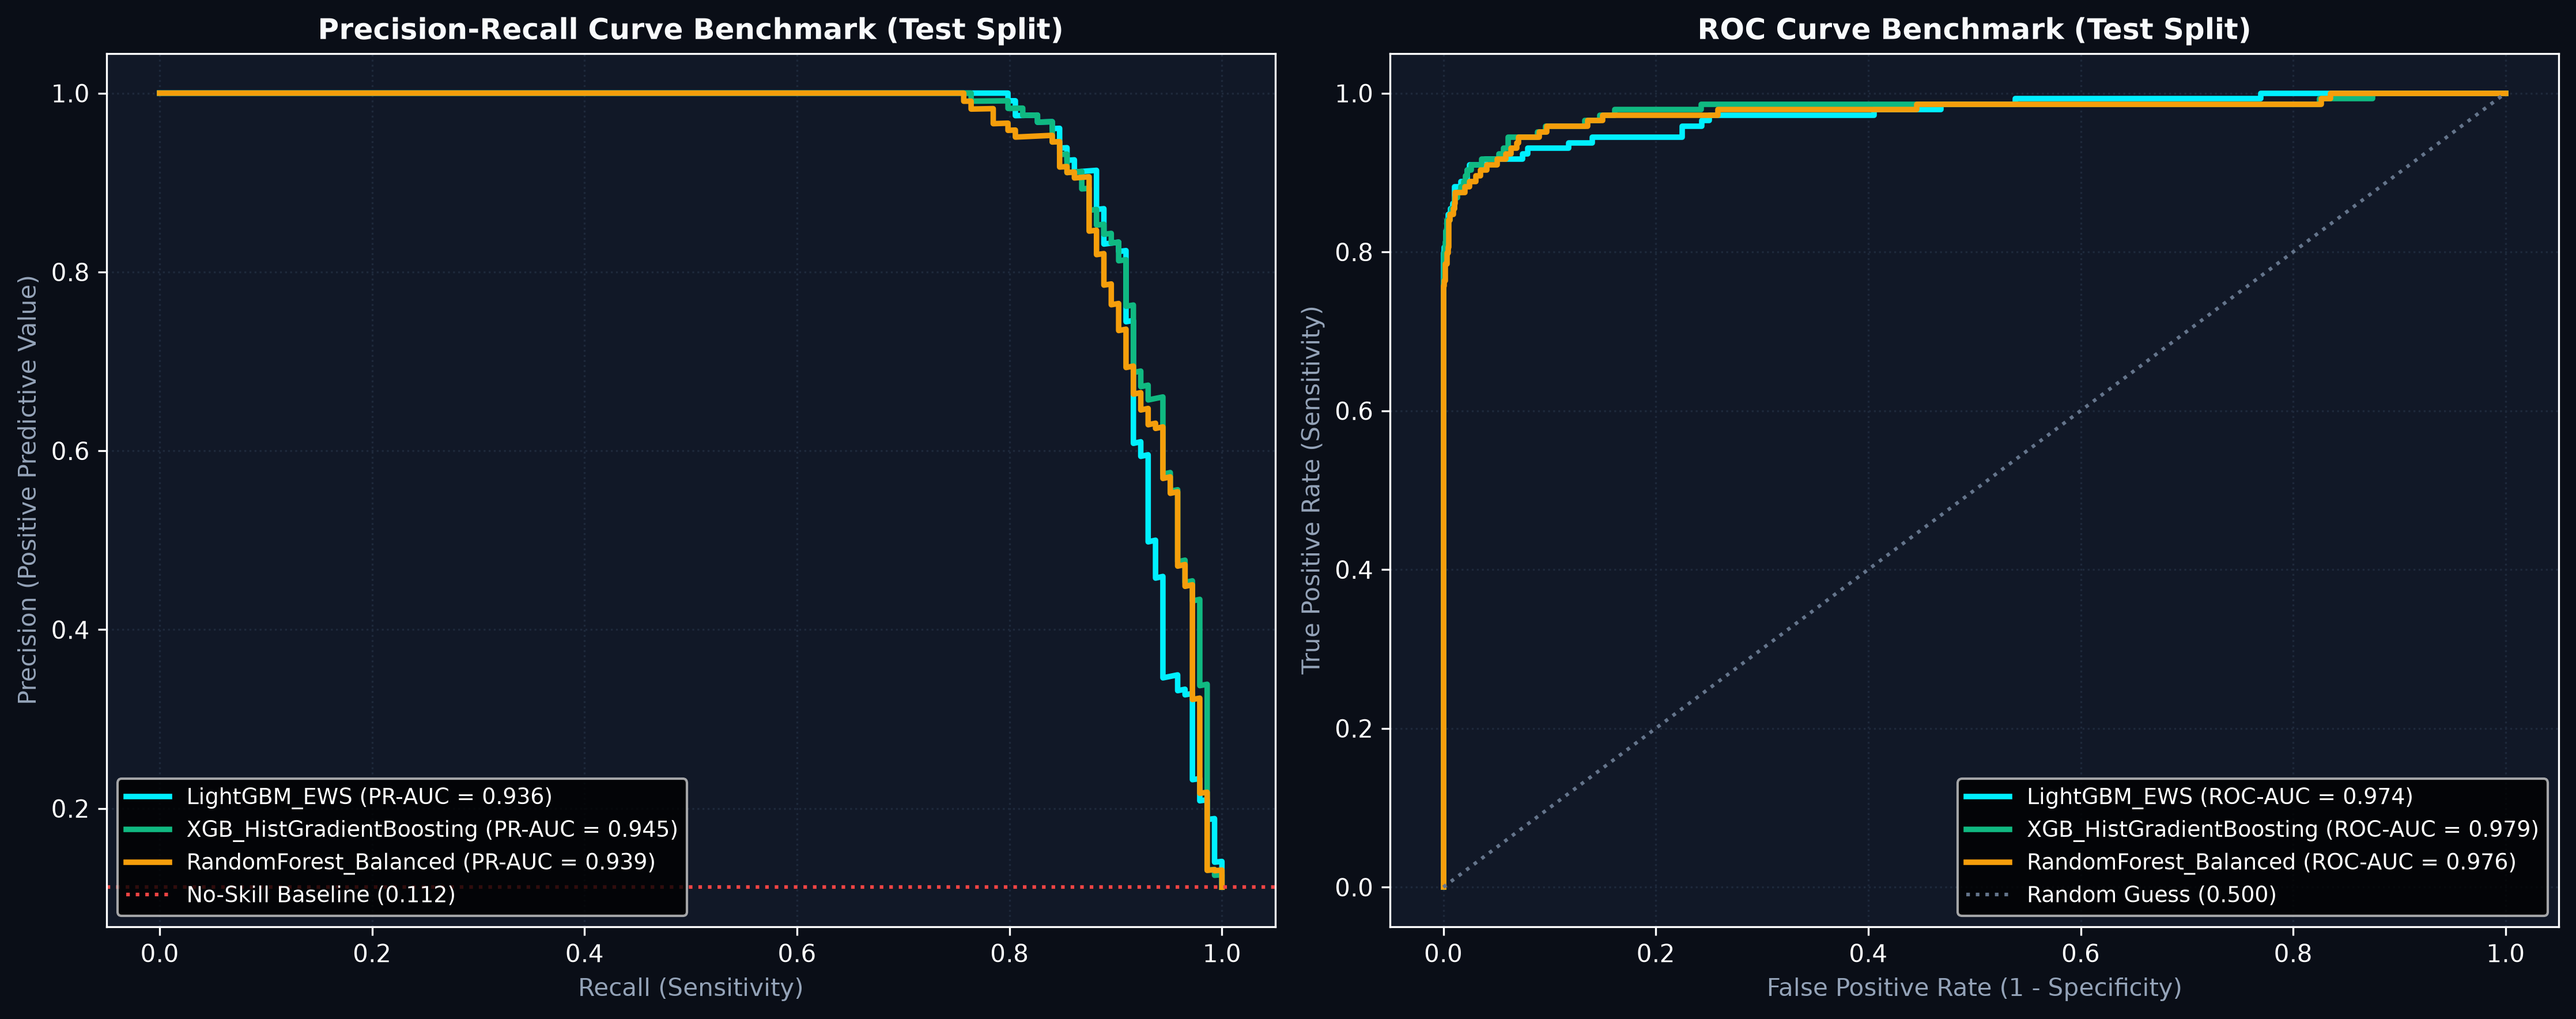


--- 04_threshold_optimization_and_multiclass_cm.png ---


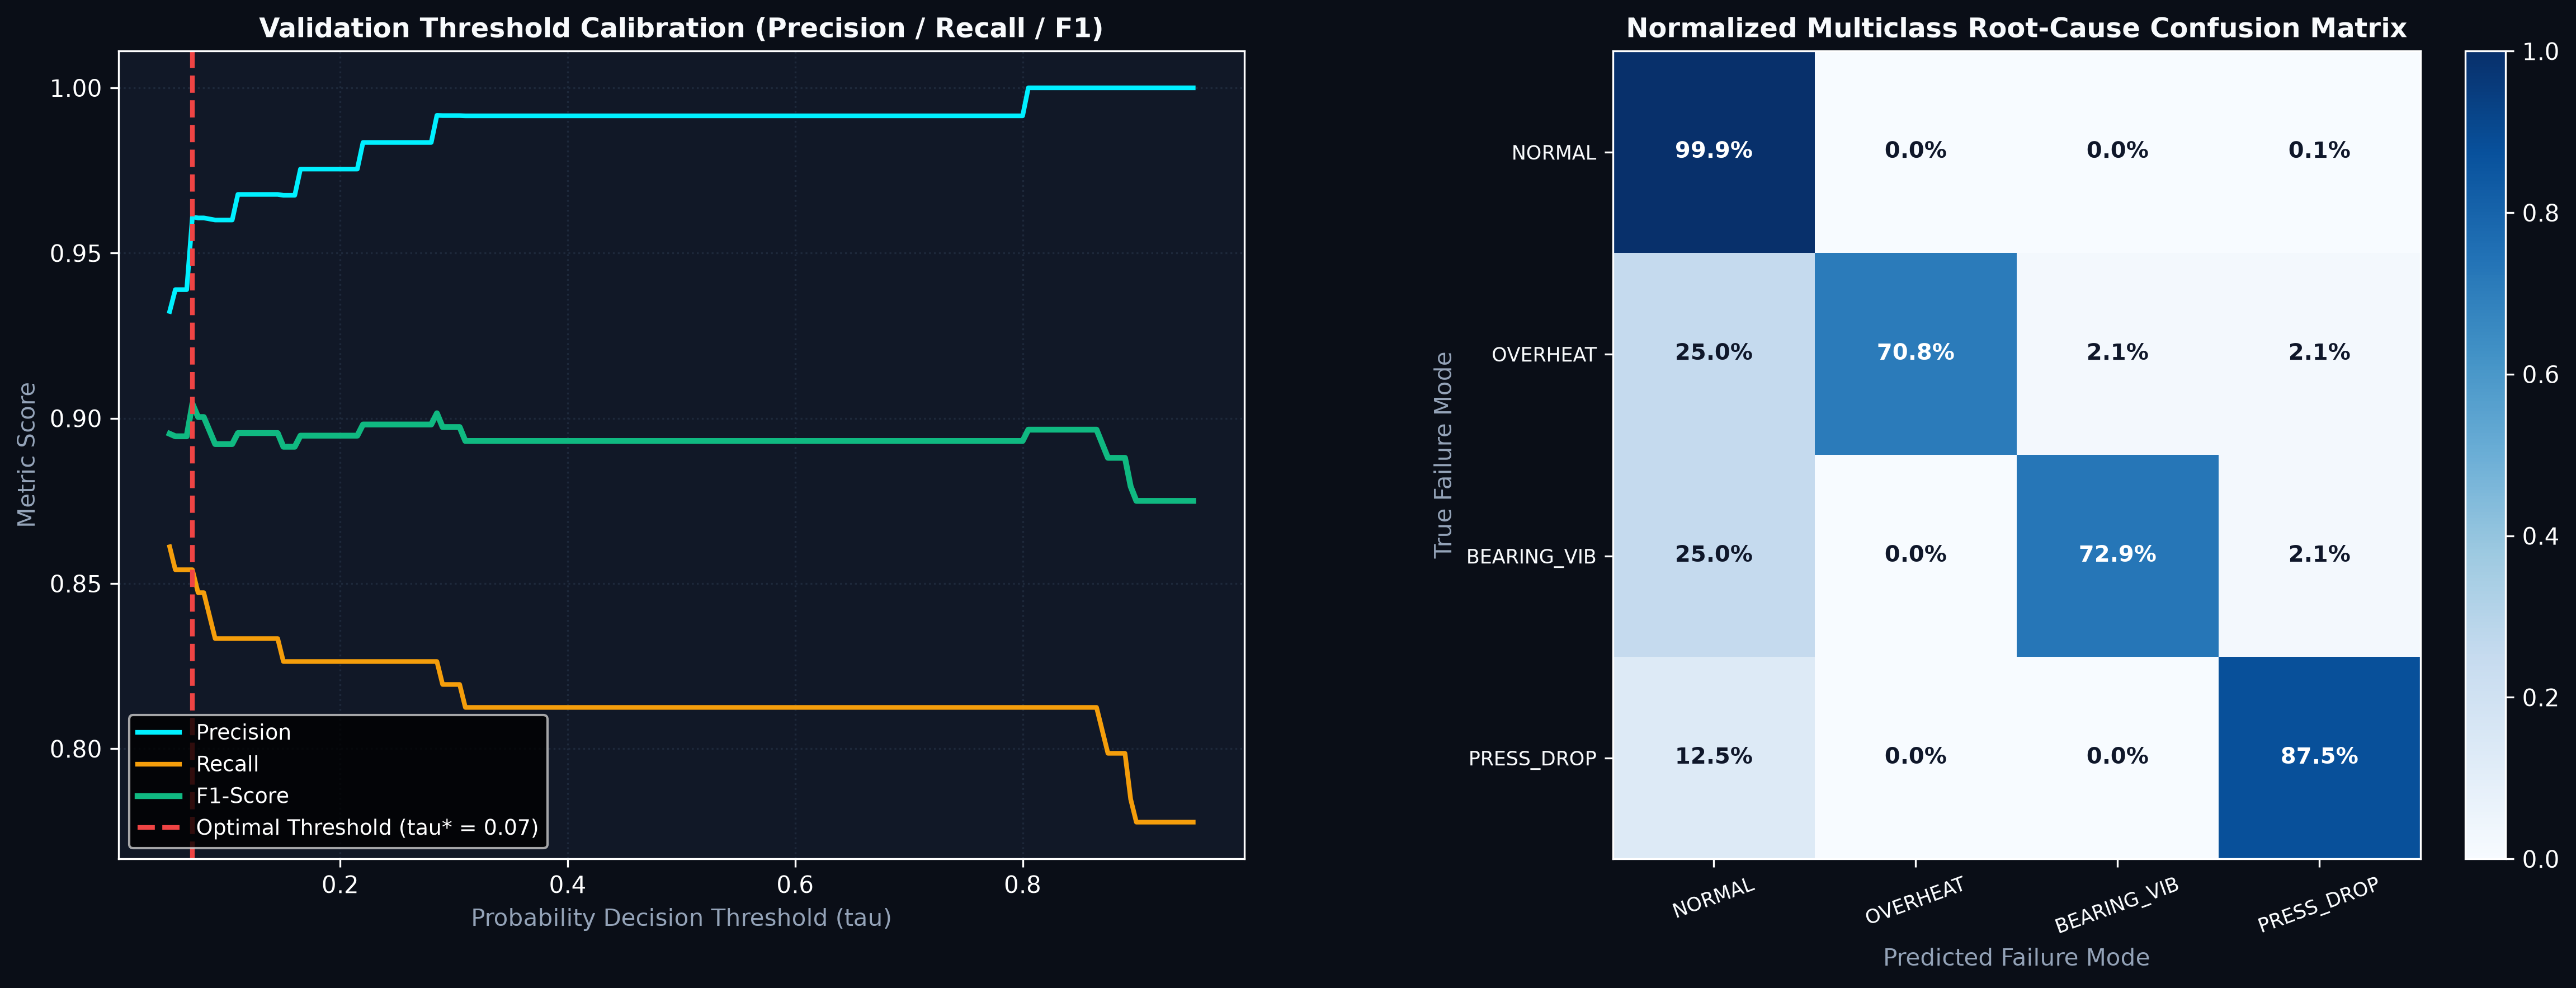


--- 05_shap_global_feature_importance.png ---


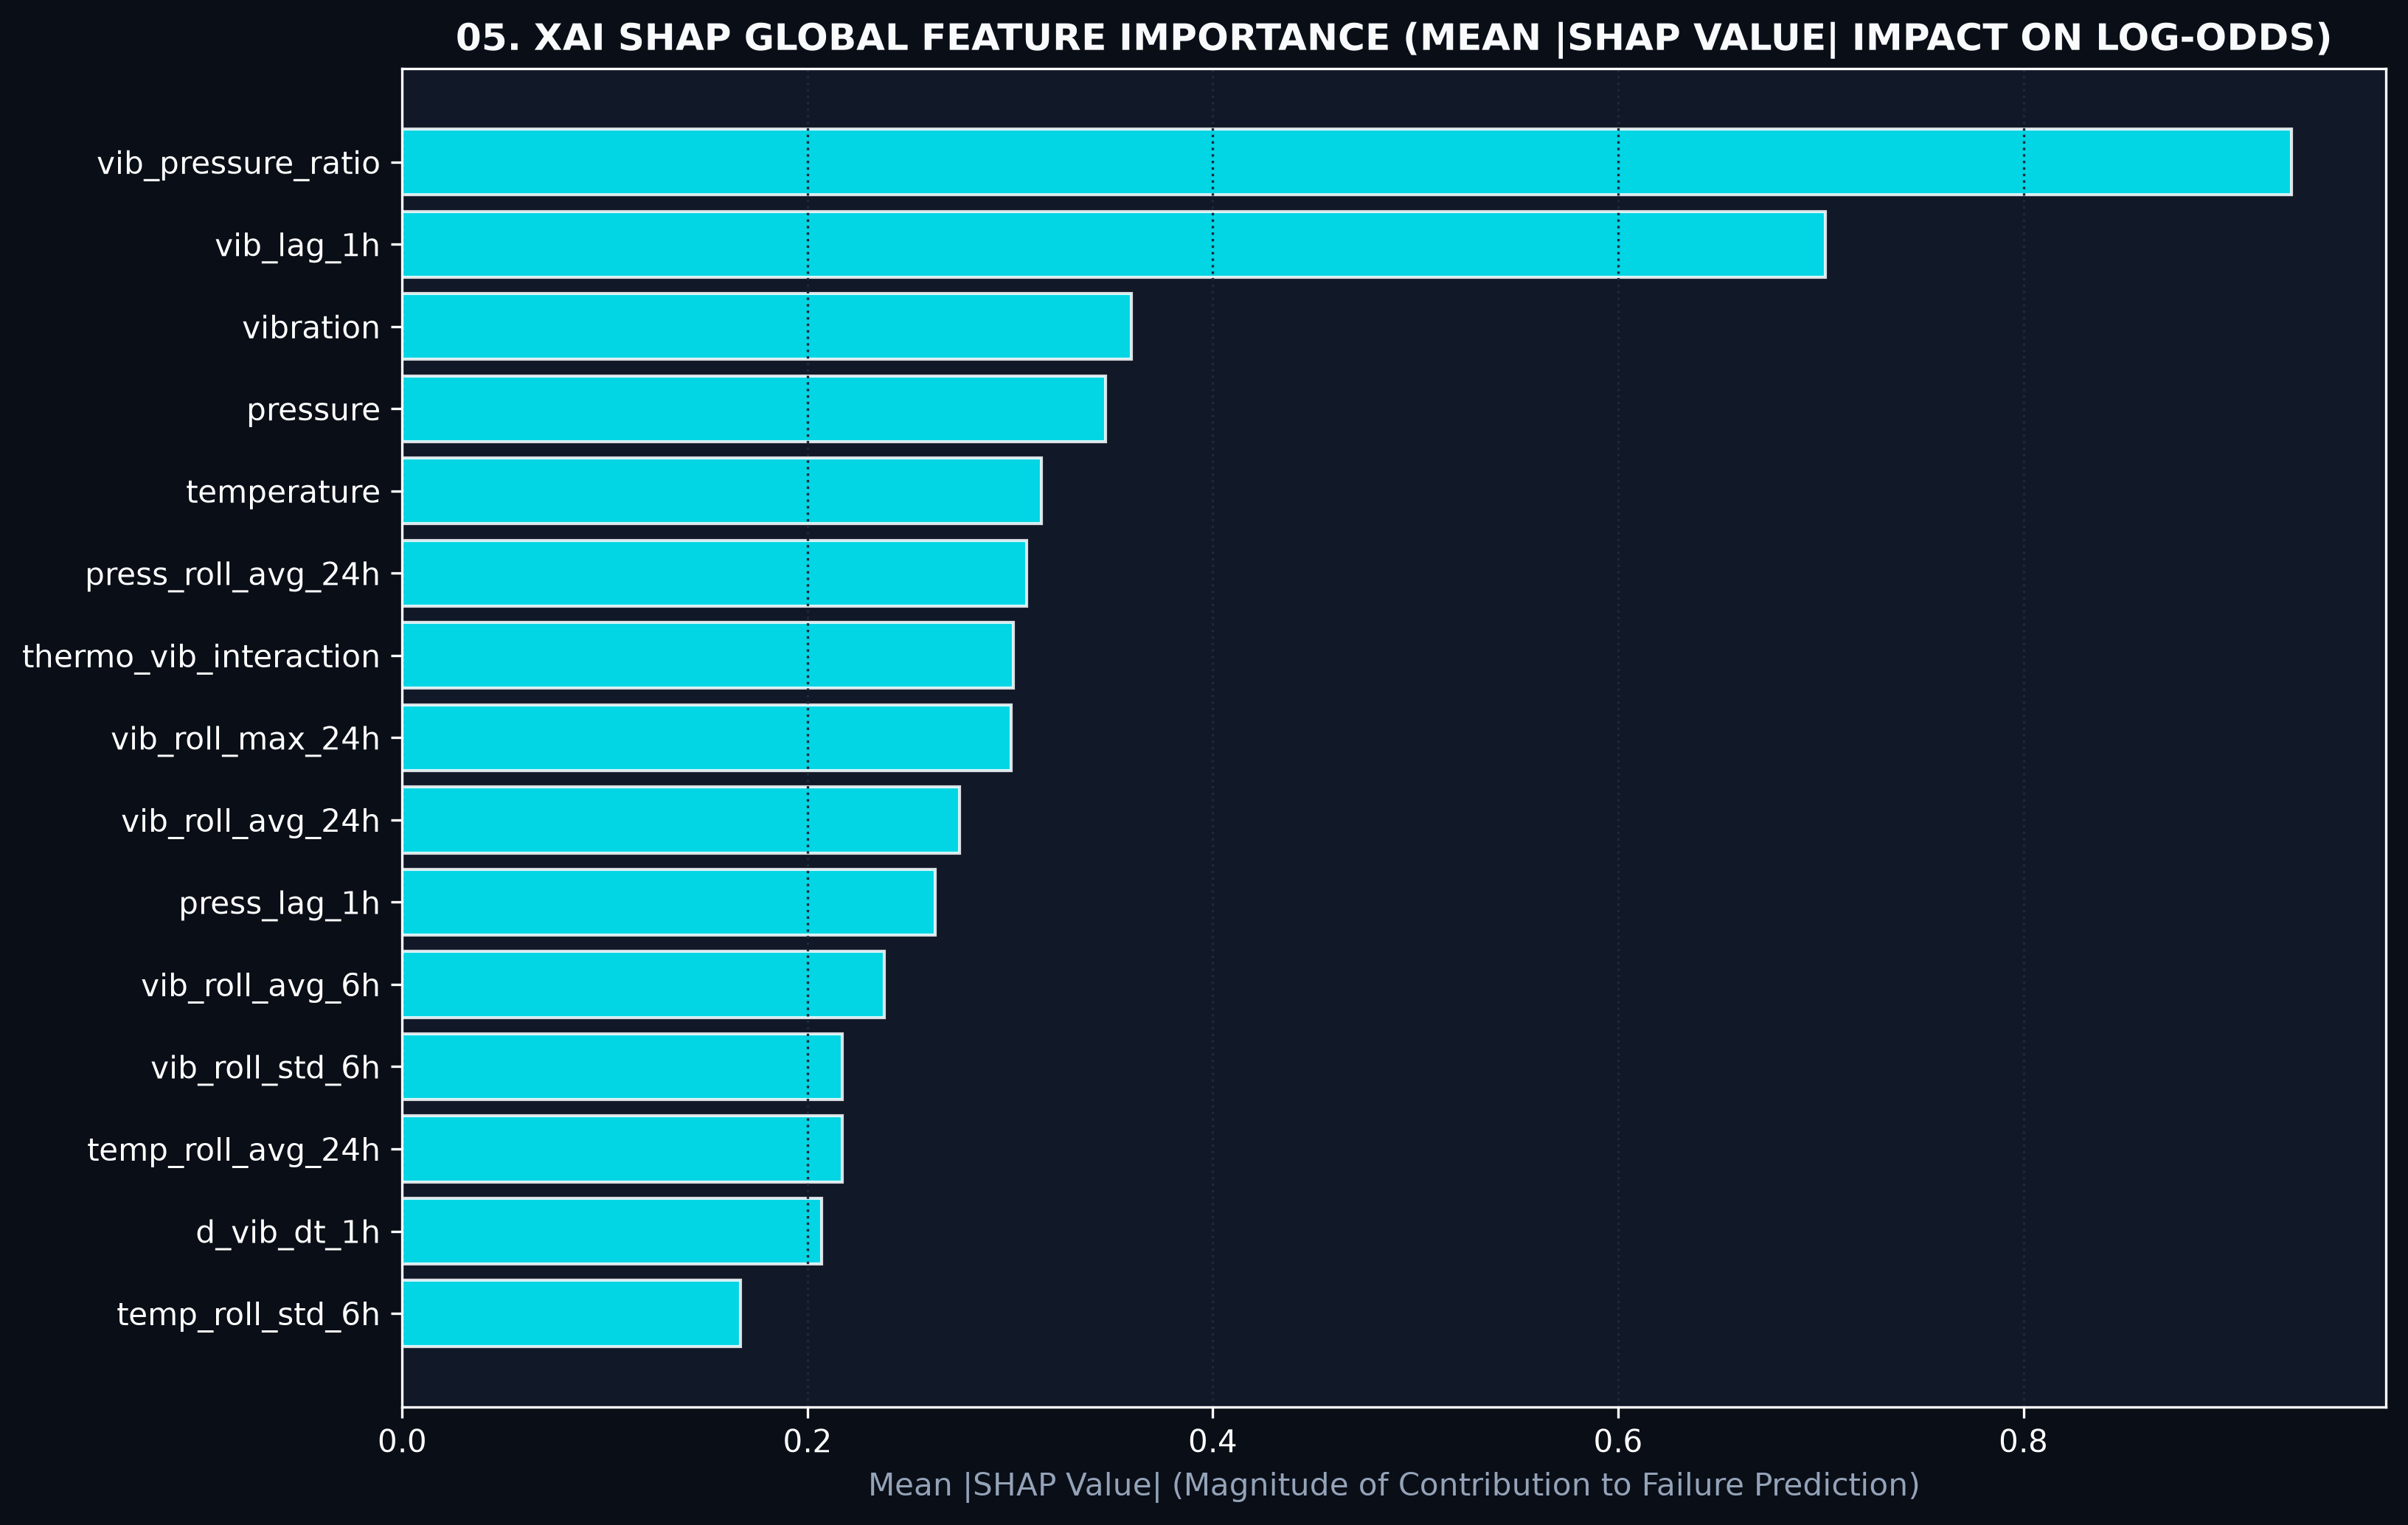


--- 06_timeseries_critical_threshold_forecast.png ---


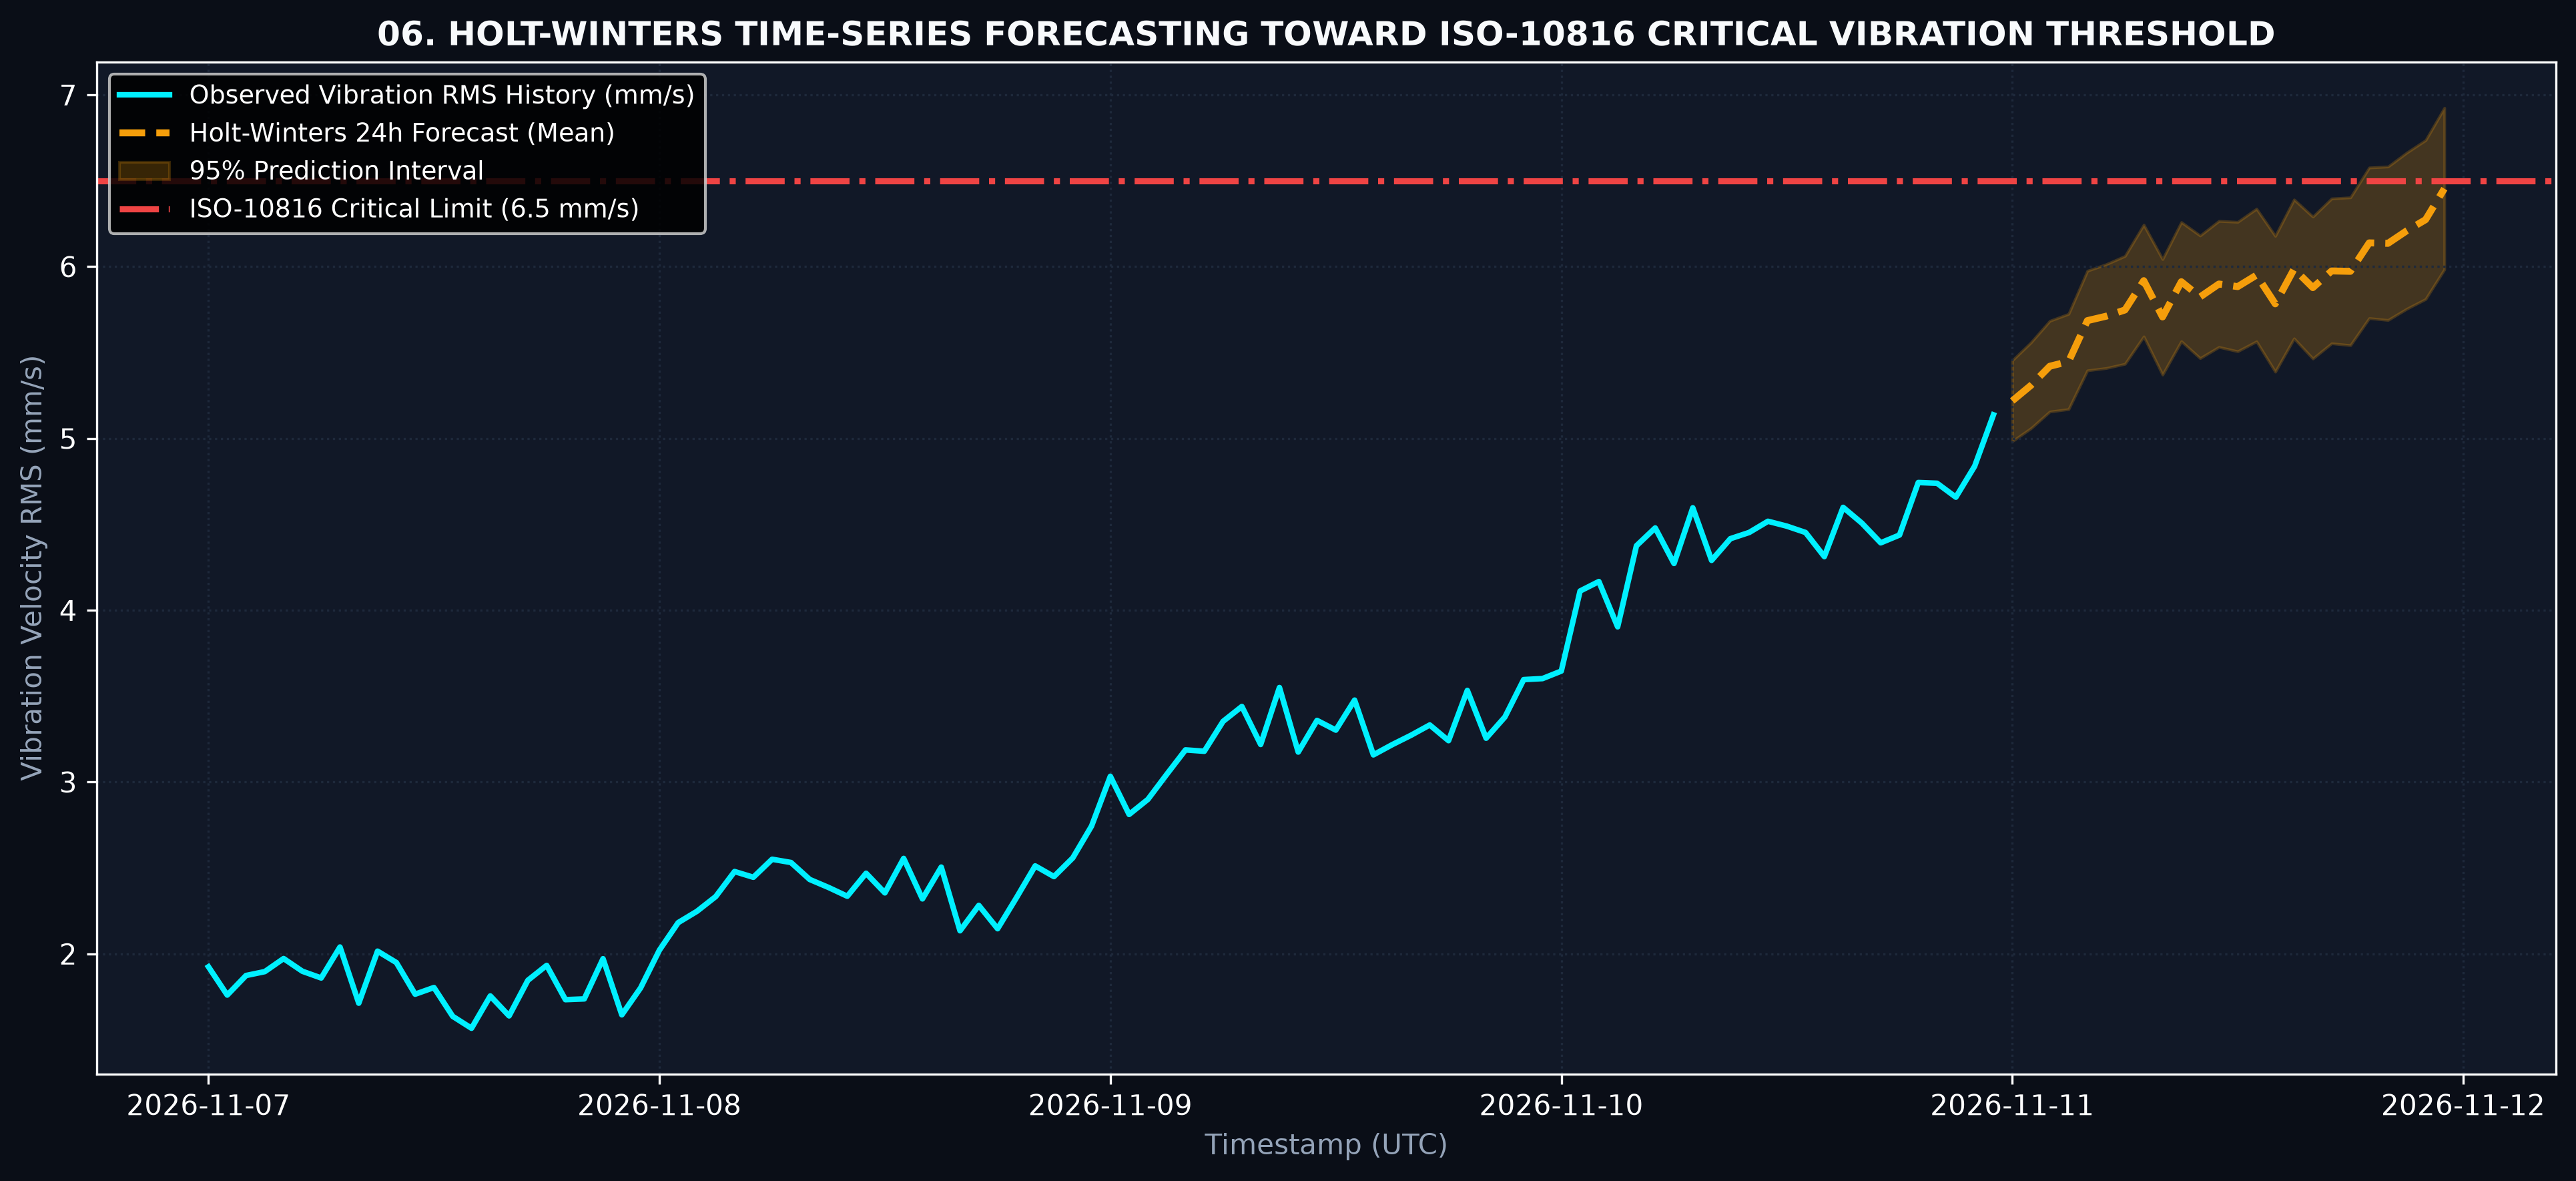

In [5]:
fig_dir = "../outputs/iot_predictive_maintenance/figures"
fig_files = [
    "01_telemetry_degradation_timeline.png",
    "02_inferential_distributions_violin.png",
    "03_model_benchmark_pr_roc_curves.png",
    "04_threshold_optimization_and_multiclass_cm.png",
    "05_shap_global_feature_importance.png",
    "06_timeseries_critical_threshold_forecast.png",
]
for fname in fig_files:
    fpath = os.path.join(fig_dir, fname)
    if os.path.exists(fpath):
        print(f"\n--- {fname} ---")
        display(Image(filename=fpath, width=900))